# Лабораторная работа №2. Сравнение архитектур VGG и ResNet (Вариант 1: CIFAR-10)

Чтобы не загромождать ноутбук сотнями строк кода, вся логика вынесена в отдельные модули в папке `src/`:
* **`src/config.py`** — датакласс `Config`, где собраны пути к папкам (`data`, `checkpoints`, `logs`) и общие гиперпараметры (`seed=100`, `batch_size=128`, `lr=1e-3`, `epochs=20`).
* **`src/dataset.py`** — загрузка и подготовка датасета через функцию `get_dataloaders(cfg)`.

---

## Разведочный анализ данных (EDA)

### Что представляет собой датасет CIFAR-10:
* **Всего картинок:** 60 000 штук (разбиваем их в `get_dataloaders` с помощью `train_test_split` со стратификацией `stratify`, чтобы во всех выборках было поровну каждого класса):
  * **Train (обучение):** 45 000 картинок (90% от исходного `train`).
  * **Validation (проверка после каждой эпохи):** 5 000 картинок (10% от исходного `train`).
  * **Test (финальный экзамен):** 10 000 картинок.
* **Классы (`CIFAR10_CLASSES`):** 10 категорий (`airplane`, `automobile`, `bird`, `cat`, `deer`, `dog`, `frog`, `horse`, `ship`, `truck`).
* **Формат картинок:** цветные изображения `32 × 32` пикселя, `3` канала (RGB). Внутри `dataset.py` функция `_to_gpu_tensors` сразу переводит их в тензоры на GPU, меняет порядок осей через `.permute(0, 3, 1, 2)` в формат `(N, 3, 32, 32)` и нормализует значения пикселей из `[0..255]` в диапазон `[-1.0, 1.0]`.


In [1]:
import random
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from torchvision import datasets
from torchvision.transforms.functional import to_tensor, rgb_to_grayscale

from src.config import Config
from src.dataset import get_dataloaders, CIFAR10_CLASSES
from src.metrics import evaluate_checkpoint, plot_confusion_matrices, plot_losses
from src.models import VGG, ResNet
from trainer import train_model

<Figure size 640x480 with 0 Axes>

### Настройка окружения и загрузка датасета

Перед тем как смотреть на данные и обучать модели, подготовим рабочее окружение:
1. **Создаём объект `cfg = Config()` (из `src/config.py`):** при вызове он автоматически проверит наличие папок `data/`, `checkpoints/` и `logs/` (через метод `__post_init__`) и выберет видеокарту `cuda`.
2. **Фиксируем случайность (`cfg.seed = 100`):** задаём одинаковый `seed` для `random`, `numpy` и `torch`. Благодаря этому разбиение на выборки и начальные веса у VGG и ResNet будут одинаковыми при каждом перезапуске.
3. **Создаём `DataLoader`'ы через `get_dataloaders(cfg)` (из `src/dataset.py`):** функция скачивает CIFAR-10, с помощью `_to_gpu_tensors` переводит картинки в нормализованные тензоры `[-1, 1]` сразу на видеокарте и пакует их в батчи по 128 штук (`train_loader`, `val_loader`, `test_loader`).
4. **Подгружаем «сырые» данные (`raw_train`, `raw_test`):** берём исходный `datasets.CIFAR10` без нормализации. Если рисовать картинки напрямую из `train_loader`, из-за сдвига цветов в `[-1, 1]` они будут выглядеть засвеченными, а `raw_train` нужен специально для красивых графиков в EDA.


In [2]:
cfg = Config()
random.seed(cfg.seed)
np.random.seed(cfg.seed)
torch.manual_seed(cfg.seed)

train_loader, val_loader, test_loader = get_dataloaders(cfg)

raw_train = datasets.CIFAR10(root=cfg.data_dir, train=True, download=False)
raw_test = datasets.CIFAR10(root=cfg.data_dir, train=False, download=False)

### Распределение классов и примеры картинок

Проверим сбалансированность выборки и посмотрим на сами изображения:
1. **Баланс классов:** посчитаем количество картинок каждого класса в списке `raw_train.targets` через `Counter` и отрисуем столбчатую диаграмму (`plt.bar`), подписав оси названиями из `CIFAR10_CLASSES` (`src/dataset.py`).
2. **Случайные примеры:** соберём сетку `2 × 5` (`plt.subplots`), для каждого из 10 классов выберем случайный индекс через `random.choice` и выведем картинку вместе с её текстовой меткой и `id`.


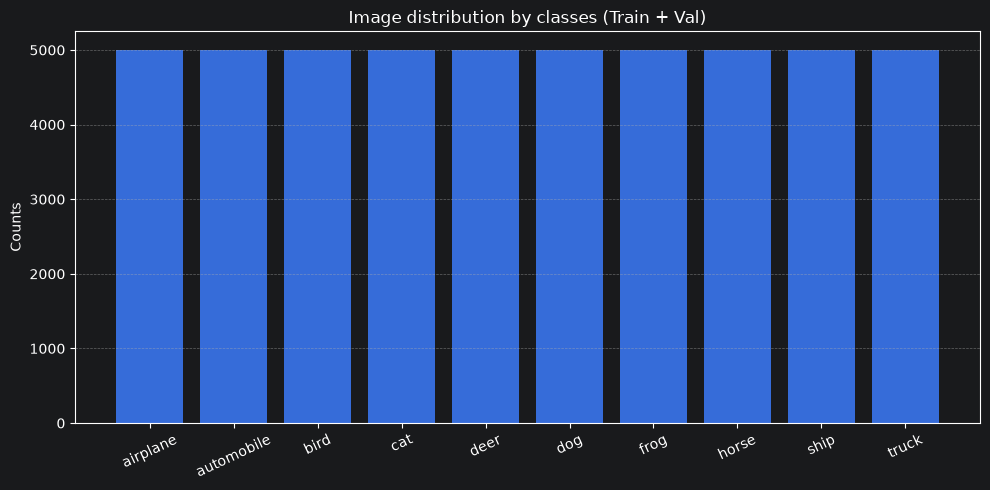

In [3]:
counts = Counter(raw_train.targets)

plt.figure(figsize=(10, 5))
plt.bar(CIFAR10_CLASSES, [counts[i] for i in range(cfg.num_classes)])
plt.title("Image distribution by classes (Train + Val)")
plt.ylabel("Counts")
plt.xticks(rotation=25)
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

По графику видно, что датасет идеально сбалансирован: в `raw_train` на каждый из 10 классов приходится ровно по **5 000 картинок** (после нашего разбиения через `train_test_split` со `stratify` в `src/dataset.py` получается ровно по 4 500 картинок на класс в `train` и по 500 в `val`).

Теперь посмотрим на сами изображения. Создадим сетку `2 × 5` через `plt.subplots`, пройдёмся по всем 10 классам (`axes.flat`), выберем для каждого случайный индекс с помощью `random.choice` и отрисуем картинку (`ax.imshow`) с названием класса из списка `CIFAR10_CLASSES`.


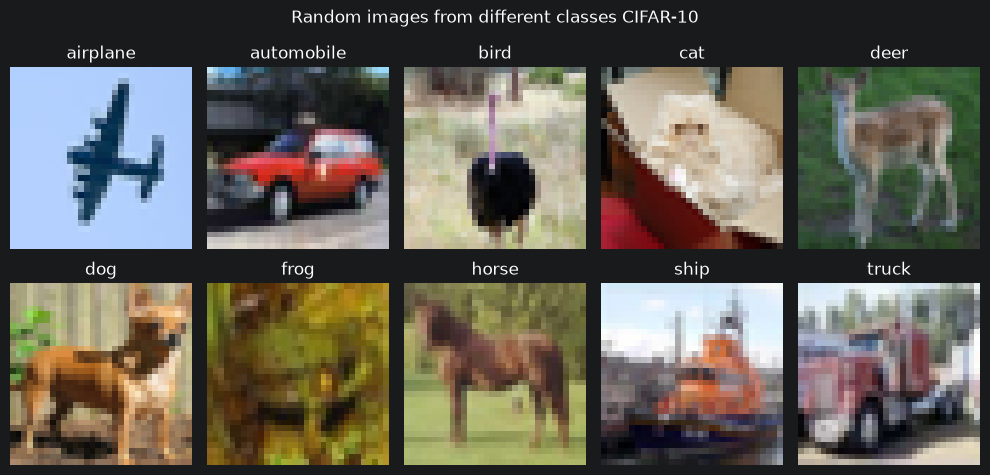

In [4]:
fig, axes = plt.subplots(2, 5, figsize=(10, 5))
fig.suptitle("Random images from different classes CIFAR-10")

for class_idx, ax in enumerate(axes.flat):
    idx = random.choice([i for i, label in enumerate(raw_train.targets) if label == class_idx])
    img, label = raw_train[idx]
    ax.imshow(img)
    ax.set_title(CIFAR10_CLASSES[label])
    ax.axis("off")

plt.tight_layout()
plt.show()

### Что видно по данным (выводы по EDA):

1. **Идеальный баланс классов:** В датасете ровно по 6 000 картинок каждого класса (после `train_test_split` со `stratify` в `src/dataset.py` получаем по 4 500 в `train`, 500 в `val` и 1 000 в `test`). Благодаря этому метрика `accuracy_score` из `src/metrics.py` будет честной и не перекошенной в сторону какого-то одного класса.
2. **Очень маленькое разрешение (32×32):** Картинки сильно пикселизированы, мелкие детали (черты морды, мелкие части кузова) размыты. Из-за этого свёрточным слоям (`nn.Conv2d` в `src/models.py`) придётся цепляться за общие контуры и цвета.
3. **Похожие между собой классы:** Пары `cat` и `dog`, `deer` и `horse`, а также `automobile` и `truck` на картинках 32×32 выглядят очень похоже (одинаковый фон и силуэты), поэтому именно на них модели будут ошибаться чаще всего.
4. **Разный свет и ракурсы:** Одни и те же объекты сняты сбоку, спереди, в тени или на ярком солнце. Чтобы нейросеть лучше справлялась с таким разбросом, в `src/dataset.py` функция `_to_gpu_tensors` центрирует яркость всех каналов в диапазон `[-1, 1]`, а в `src/trainer.py` мы добавим аугментации (`gpu_augment`).


## Исследование операции свёртки

Посмотрим, как работает двумерная свёртка (`F.conv2d`) на практике. Возьмём одну картинку из датасета (`raw_train[1]` — класс `truck`), переведём её в Ч/Б через `rgb_to_grayscale` и в тензор через `to_tensor`. Так как `F.conv2d` ждёт на вход 4D-тензор батча `(N, C, H, W)`, добавим фиктивную размерность спереди через `.unsqueeze(0)` — получится форма `(1, 1, 32, 32)`.

Зададим вручную три классических фильтра (ядра $3 \times 3$) и прогоним через них картинку с `padding=1`:
1. **Размытие (`blur_kernel`):** матрица из единиц, поделённая на 9 (`torch.ones / 9.0`). Окно просто считает среднее арифметическое 9 соседних пикселей и «замыливает» картинку.
2. **Вертикальные границы (`vertical_kernel`):** слева стоят `-1`, посередине `0`, справа `+1`. Фильтр вычитает левые пиксели из правых: однородный фон зануляется (становится серым), а вертикальные линии кузова грузовика ярко подсвечиваются.
3. **Горизонтальные границы (`horizontal_kernel`):** сверху `-1`, посередине `0`, снизу `+1`. Вычитает верхние пиксели из нижних и находит горизонтальные края (бампер, крышу, решётку радиатора).
4. **Проверка параметров `kernel_size`, `stride` и `padding`:** в конце ячейки прогоним тестовые свёртки с разными настройками, чтобы увидеть, как меняется размер картинки (`out.shape`) перед тем, как использовать эти же слои `nn.Conv2d` в `src/models.py`.


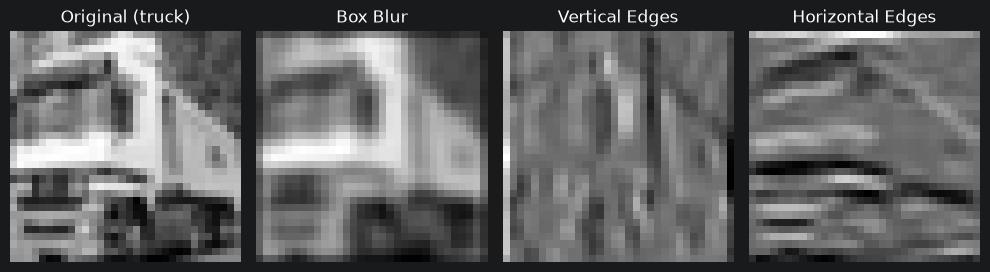

In [5]:
raw_img, label = raw_train[1]
gray_tensor = to_tensor(rgb_to_grayscale(raw_img)).unsqueeze(0)

blur_kernel = torch.ones((1, 1, 3, 3)) / 9.0

vertical_kernel = torch.tensor([[
    [-1.0, 0.0, 1.0],
    [-1.0, 0.0, 1.0],
    [-1.0, 0.0, 1.0]
]]).unsqueeze(0)

horizontal_kernel = torch.tensor([[
    [-1.0, -1.0, -1.0],
    [0.0, 0.0, 0.0],
    [1.0, 1.0, 1.0]
]]).unsqueeze(0)

filters = {
    f"Original ({CIFAR10_CLASSES[label]})": gray_tensor,
    "Box Blur": F.conv2d(gray_tensor, blur_kernel, padding=1),
    "Vertical Edges": F.conv2d(gray_tensor, vertical_kernel, padding=1),
    "Horizontal Edges": F.conv2d(gray_tensor, horizontal_kernel, padding=1),
}

fig, axes = plt.subplots(1, 4, figsize=(10, 5))
for ax, (title, tensor_img) in zip(axes, filters.items()):
    ax.imshow(tensor_img.squeeze(), cmap="gray")
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

**Как меняется картинка после применения фильтров?**
* **Размытие (`Box Blur`):** картинка становится «мыльной», резкие края пропадают. Это происходит потому, что фильтр `blur_kernel` заменяет каждый пиксель на среднее арифметическое 9 соседних пикселей в окне $3 \times 3$.
* **Вертикальные границы (`Vertical Edges`):** однородный фон (небо, асфальт), где яркость слева и справа одинаковая, уходит в ноль (заливается ровным серым цветом). Зато ярко выделяются вертикальные элементы: стойки кабины грузовика, края кузова и колёс.
* **Горизонтальные границы (`Horizontal Edges`):** точно так же гасит однородный фон, но реагирует только на перепады яркости сверху вниз — чётко проступают горизонтальные линии бампера, решётки радиатора и крыши грузовика.

**Какую роль играет ядро свёртки?**
Ядро свёртки (kernel / фильтр) работает как **шаблон для поиска конкретных деталей**. От того, какие числа стоят внутри матрицы ядра, зависит, что именно фильтр будет искать на фото: вертикальные полоски, углы, пятна или текстуры. В наших моделях `VGG` и `ResNet` (в файле `src/models.py`) мы уже не задаём эти матрицы вручную — там слои `nn.Conv2d` сами подбирают нужные веса во время обучения в `src/trainer.py` (через `loss.backward()` и `optimizer.step()`).


In [6]:
test_params = [
    (3, 1, 0),
    (3, 1, 1),
    (5, 1, 0),
    (3, 2, 1)
]

for kernel, stride, padding in test_params:
    dummy_kernel = torch.ones((1, 1, kernel, kernel))
    out = F.conv2d(gray_tensor, dummy_kernel, padding=padding, stride=stride)
    h_out, w_out = out.shape[2], out.shape[3]
    print(f"kernel_size={kernel}, stride={stride}, padding={padding} ---> Output shape: {h_out}x{w_out}")

kernel_size=3, stride=1, padding=0 ---> Output shape: 30x30
kernel_size=3, stride=1, padding=1 ---> Output shape: 32x32
kernel_size=5, stride=1, padding=0 ---> Output shape: 28x28
kernel_size=3, stride=2, padding=1 ---> Output shape: 16x16


**На что влияют параметры `kernel_size`, `stride` и `padding`?**
Все три параметра управляют тем, как окно фильтра двигается по матрице, и напрямую определяют выходной размер (`out.shape[2]` и `out.shape[3]` после `F.conv2d`):
* **`kernel_size`:** размер самого окна фильтра (`dummy_kernel`). Чем окно больше, тем шире область обзора, но тем сильнее «съедаются» края картинки без отступов: при окне $3 \times 3$ размер падает с $32 \times 32$ до $30 \times 30$, а при $5 \times 5$ — до $28 \times 28$.
* **`padding`:** добавляет защитную рамку из нулей вокруг краёв. Это позволяет окну пройтись по самым крайним пикселям и сохранить исходный размер. В `src/models.py` мы почти везде используем комбинацию `kernel_size=3, stride=1, padding=1`, чтобы картинка не уменьшалась сама по себе после каждого `nn.Conv2d`.
* **`stride`:** шаг, с которым прыгает фильтр. Если поставить `stride=2`, окно перешагивает через пиксель, и выходная карта сжимается ровно в 2 раза ($32 \times 32 \rightarrow 16 \times 16$). Именно так в нашей архитектуре `ResNet` (`src/models.py`, блоки `ResNetBlock`) сжимается размерность вместо использования `MaxPool2d`.

**Чем операция свёртки полезна при обработке изображений?**
* **Не ломает 2D-геометрию:** в обычных полносвязных слоях (`nn.Linear`) картинку приходится вытягивать через `nn.Flatten()` в плоский список чисел, из-за чего теряется связь между верхними и нижними соседними пикселями. Свёртка (`nn.Conv2d`) работает прямо с двумерной таблицей.
* **Экономия памяти (общие веса):** один маленький фильтр $3 \times 3$ (всего 9 весов на канал) скользит по всей картинке. Благодаря этому в наших моделях из `src/models.py` около 4.9 млн параметров (что считается в функции `count_parameters` в `src/metrics.py`), а не сотни миллионов, как было бы в полносвязной сети.
* **Неважно, где находится объект:** если грузовик или кот сдвинется в другой угол кадра, тот же самый скользящий фильтр всё равно найдёт его контуры на новом месте.


## Изучение архитектур CNN: VGG и ResNet

Обе модели реализованы в файле **`src/models.py`** и адаптированы под небольшие картинки $32 \times 32$ из датасета CIFAR-10.

### Чем свёрточные сети (CNN) отличаются от обычных полносвязных (MLP)
В обычной полносвязной сети картинку $32 \times 32 \times 3$ пришлось бы сразу вытянуть через `nn.Flatten()` в плоский список из 3072 чисел. Из-за этого сеть перестаёт понимать, какие пиксели находились рядом по вертикали и диагонали, а количество весов в слоях `nn.Linear` становится огромным. Свёрточные сети работают напрямую с 2D-картинками: маленький фильтр (`nn.Conv2d`) скользит по всему изображению, сохраняет геометрию объектов и использует одни и те же веса для всего кадра.

---

### Архитектура 1: VGG (класс `VGG` в `src/models.py`)
Последовательная архитектура, где все слои идут строго друг за другом без ответвлений.

* **Как устроена в коде:** состоит из двух частей (`nn.Sequential`):
  1. **`self.features` (извлечение признаков):** 4 блока со свёртками и пулингом. Картинка последовательно сжимается по размеру ($32 \rightarrow 16 \rightarrow 8 \rightarrow 4 \rightarrow 2$), а число каналов удваивается ($3 \rightarrow 64 \rightarrow 128 \rightarrow 256 \rightarrow 512$).
  2. **`self.classifier` (классификатор):** вытягивает полученный тензор $512 \times 2 \times 2$ через `nn.Flatten()` в вектор из 2048 чисел и прогоняет через два полносвязных слоя `nn.Linear(2048, 512)` и `nn.Linear(512, 10)`.
* **Используемые операции:** `nn.Conv2d` (ядро $3 \times 3$, `padding=1`), `nn.BatchNorm2d` (нормализация батча для стабильного обучения), активация `nn.ReLU(inplace=True)`, сжатие `nn.MaxPool2d(kernel_size=2, stride=2)` и `nn.Linear`.
* **Главная идея архитектуры:** полный отказ от больших фильтров ($5 \times 5$, $7 \times 7$) в пользу маленьких ядер **$3 \times 3$**. Два слоя $3 \times 3$ подряд охватывают ту же область $5 \times 5$, но требуют меньше весов ($18$ вместо $25$) и дают дополнительную нелинейность `ReLU`.
* **Плюсы:** очень простая и понятная структура («прямая труба» из слоёв); быстро считает за счёт раннего сжатия картинок через `MaxPool2d`.
* **Минусы:** много параметров тратится на полносвязный слой `Linear(2048, 512)` на выходе; если сделать такую сеть слишком глубокой, градиенты при вызове `loss.backward()` начнут затухать по пути к первым слоям.

---

### Архитектура 2: ResNet (классы `ResNetBlock` и `ResNet` в `src/models.py`)
Архитектура с обходными связями, которая позволяет строить очень глубокие сети без затухания градиентов.

* **Как устроена в коде:**
  1. Начальный блок **`self.prep`** переводит 3 канала в 64, сохраняя размер $32 \times 32$ (без `MaxPool2d`).
  2. Четыре стадии **`self.layer1` – `self.layer4`**, собранные из кирпичиков `ResNetBlock`. Внутри каждого блока есть основная ветка `self.conv_block` (две свёртки $3 \times 3$) и обходная ветка `self.shortcut`. В методе `forward` они складываются: `out = self.conv_block(x) + self.shortcut(x)`.
  3. На выходе стоит адаптивный пулинг **`self.pool = nn.AdaptiveAvgPool2d((1, 1))`**, который усредняет каждую карту $4 \times 4$ в одно число, и всего один слой `self.fc = nn.Linear(512, 10)`.
* **Используемые операции:** `nn.Conv2d` ($3 \times 3$ для признаков и $1 \times 1$ в `shortcut` для подгонки размеров при смене числа каналов), `nn.BatchNorm2d`, `nn.ReLU`, сложение тензоров `+`, `nn.AdaptiveAvgPool2d`, `torch.flatten` и `nn.Linear`.
* **Главные идеи архитектуры:**
  1. **Skip Connections (`self.shortcut`):** слоям внутри `conv_block` не нужно заново пересобирать весь сигнал с прошлого слоя — им достаточно выучить только небольшую поправку (остаток) к входному тензору `x`.
  2. **Сжатие через `stride=2` и Global Average Pooling:** вместо `MaxPool2d` картинка уменьшается прямо внутри свёрток (`stride=2` в `layer2`–`layer4`), а отказ от больших слоёв `Linear` в конце экономит миллионы параметров.
* **Плюсы:** градиент при обратном проходе свободно проходит через операцию сложения `+` напрямую к ранним слоям, поэтому сеть учится качественнее и даёт более высокую точность.
* **Минусы:** в памяти видеокарты приходится параллельно хранить входной тензор `x`, пока считается `conv_block(x)`, а отсутствие раннего пулинга делает расчёты на первых слоях более долгими.

---

### Сравнение наших реализаций VGG и ResNet (`src/models.py`)

| Что сравниваем | `VGG` | `ResNet` |
| :--- | :--- | :--- |
| **Как идёт сигнал в `forward`** | Строго по очереди: `features` $\rightarrow$ `classifier` | Разветвляется и складывается в `ResNetBlock`: `conv_block(x) + shortcut(x)` |
| **Прохождение градиента** | Через все слои подряд (может затухать) | Напрямую через сумму `+` в обход свёрток |
| **Как сжимается картинка** | Слоями `nn.MaxPool2d(2, 2)` после каждого блока | Самими свёртками `nn.Conv2d` с шагом `stride=2` |
| **Выход сети (классификатор)** | `nn.Flatten()` + два слоя `nn.Linear` ($2048 \rightarrow 512 \rightarrow 10$) | `nn.AdaptiveAvgPool2d((1, 1))` + один слой `nn.Linear(512, 10)` |


## Построение и обучение архитектур VGG и ResNet

Вся логика обучения вынесена в модуль **`src/trainer.py`**:
* Функция **`run_epoch`** отвечает за прогон одной эпохи: если передан `optimizer`, она включает режим `model.train()`, считает ошибку и обновляет веса (`loss.backward()`, `optimizer.step()`). Если вместо оптимизатора передан `None` (на валидации), включается режим `model.eval()` без расчёта градиентов.
* Функция **`train_model`** запускает цикл по всем эпохам, сохраняет веса лучшей эпохи (`torch.save`) в папку `checkpoints/`, а историю метрик и время обучения — в JSON-файл в папку `logs/`.

Сначала проведём **базовое обучение с нуля без аугментаций (`augment=False`)** на одинаковых настройках из `Config`:
* **Оптимизатор:** `AdamW` (`lr = 1e-3`, `weight_decay = 1e-4`)
* **Функция потерь:** `nn.CrossEntropyLoss()`
* **Размер батча (`batch_size`):** 128
* **Количество эпох (`epochs`):** 20
* **Выбор лучшей модели:** по максимальной `val_acc` на валидационной выборке.


In [ ]:
torch.backends.cudnn.benchmark = True

torch.manual_seed(cfg.seed)
vgg_model = VGG(num_classes=cfg.num_classes)
vgg_history = train_model(vgg_model, "vgg_augmented", train_loader, val_loader, cfg, augment=False)

torch.manual_seed(cfg.seed)
resnet_model = ResNet(num_classes=cfg.num_classes)
resnet_history = train_model(resnet_model, "resnet_augmented", train_loader, val_loader, cfg, augment=False)

Отрисуем кривые обучения с помощью функции **`plot_losses`** из модуля **`src/metrics.py`**. Внутри себя она вызывает вспомогательную функцию `load_log`, которая читает сохранённые метрики напрямую из JSON-файлов (`logs/vgg_history.json` и `logs/resnet_history.json`), и строит сетку графиков `2 × 2` с отметкой лучшей эпохи (`axvline`).


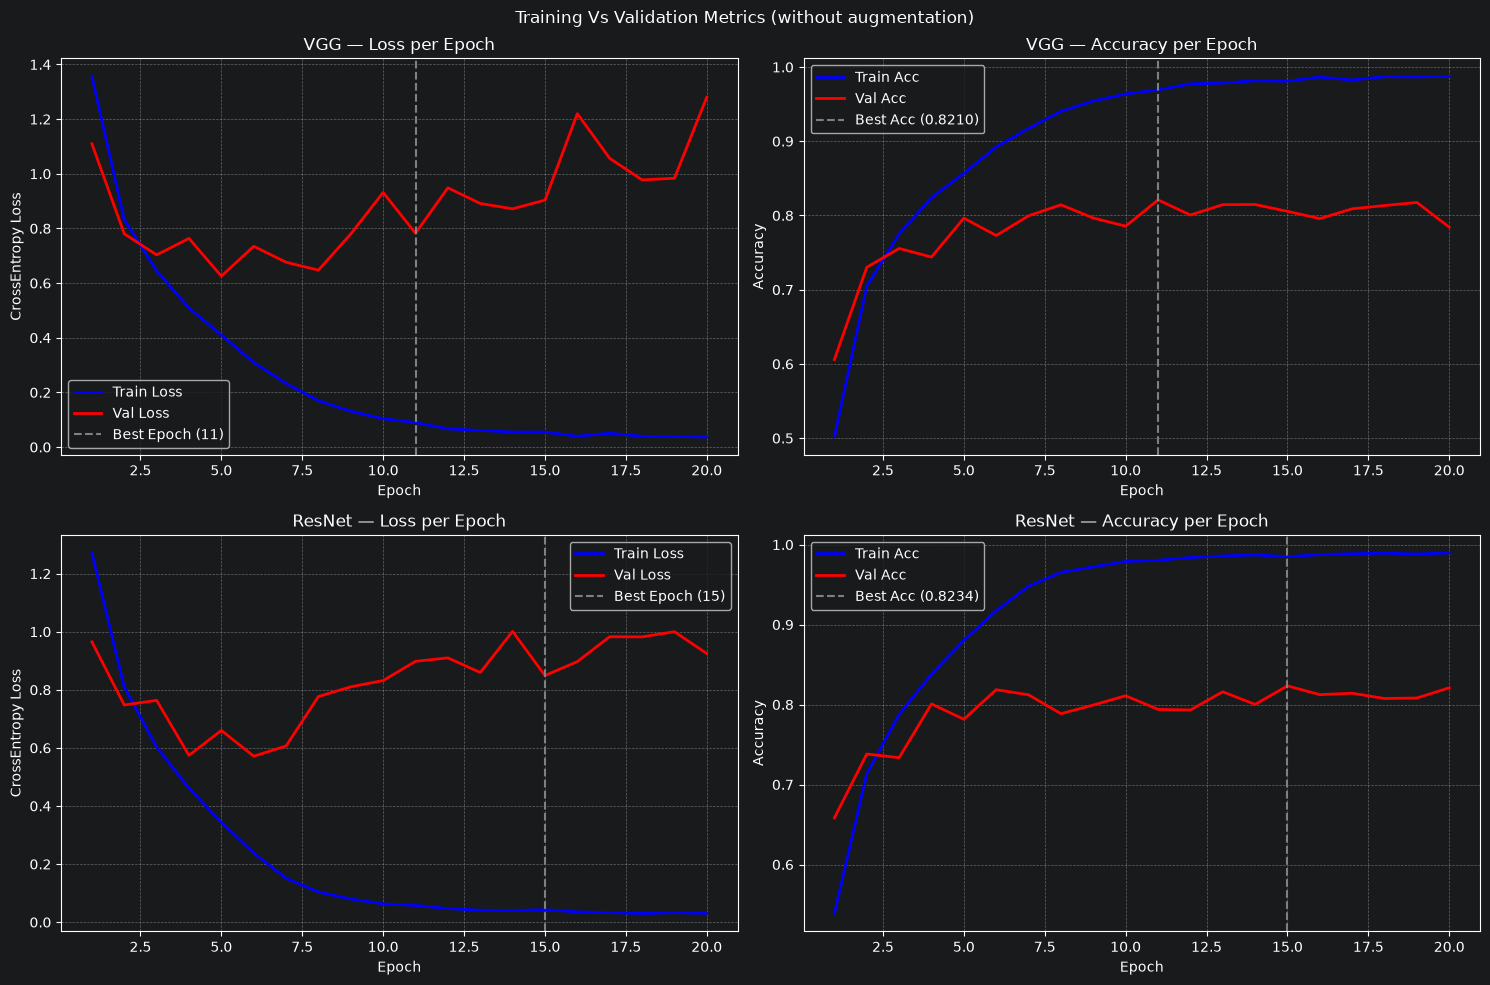

In [7]:
plot_losses(cfg, "vgg_history.json", "resnet_history.json", "Training Vs Validation Metrics (without augmentation)")

### Анализ базового обучения (`augment=False`)

1. **Сошлись ли модели?**
   Да, обе сети нормально обучились и сошлись:
   * У **`VGG`** ошибка `train_loss` упала с `1.3564` до `0.0370` (точность на обучении дошла до `98.74%`). Лучший результат на валидации (`best_val_acc`) — **`0.8210` (82.10%) на 11-й эпохе** (именно эти веса функция `train_model` из `src/trainer.py` сохранила в `checkpoints/vgg_best.pt`).
   * У **`ResNet`** ошибка `train_loss` снизилась с `1.2714` до `0.0307` (`train_acc` — `98.97%`), а лучшая точность на валидации составила **`0.8234` (82.34%) на 15-й эпохе** (`checkpoints/resnet_best.pt`).

2. **Есть ли признаки переобучения?**
   Да, после **6–7 эпохи** у обеих моделей начинается явное **переобучение**:
   * **Растёт ошибка `val_loss`:** у `VGG` минимальный `val_loss` был на 5-й эпохе (`0.6253`), а дальше ошибка поползла вверх и к 20-й эпохе выросла вдвое — до **`1.2800`**. У `ResNet` минимум был на 6-й эпохе (`0.5714`), после чего ошибка выросла до **`0.9248–1.0011`**.
   * **Огромный разрыв между `train` и `val`:** на тренировочных данных обе сети угадывают почти **`99%`** картинок, а на валидации застревают на **`~80–82%`**. То есть без аугментаций модели просто вызубрили обучающую выборку наизусть.

3. **Какая модель обучается быстрее и почему?**
   * **По реальному времени (`total_time_sec` в `src/trainer.py`):** **`VGG` обучилась в 2.6 раза быстрее** — за **`99.0 с`** (~4.9 с на эпоху) против **`258.37 с`** (~12.85 с на эпоху) у `ResNet`. Причина в архитектуре из `src/models.py`: в `VGG` сразу после первой свёртки стоит `nn.MaxPool2d(2, 2)`, который сжимает картинку с $32 \times 32$ до $16 \times 16$ (пикселей становится в 4 раза меньше, и считать дальше легко). А в `ResNet` пулинга в начале нет, поэтому блоки `self.prep` и `self.layer1` гоняют тяжёлые свёртки по полной матрице $32 \times 32$.
   * **По эпохам:** на старте быстрее схватывает **`ResNet`** за счёт обходных связей `self.shortcut` в `ResNetBlock` — уже на 1-й эпохе она выдаёт `65.84%` точности (против `60.60%` у `VGG`), а к 6-й эпохе набирает `81.86%`.


### Борьба с переобучением (`augment=True` + `CosineAnnealingLR`)

Чтобы модели не зазубривали тренировочные картинки наизусть, мы доработали процесс обучения в файле **`src/trainer.py`**:
1. **Добавили аугментацию батчей прямо на видеокарте (функция `gpu_augment`):** при включённом флаге `augment=True` внутри `run_epoch` каждый тренировочный батч на лету видоизменяется перед подачей в сеть (при этом на валидации `augment=False`, чтобы проверка оставалась честной):
   * **Случайное отражение по горизонтали:** с помощью `torch.rand(...) < 0.5` и `torch.flip(images, dims=[3])` примерно половина картинок в батче зеркально переворачивается.
   * **Случайный сдвиг (кроп):** через `F.pad(..., mode="reflect")` вокруг картинки $32 \times 32$ добавляется рамка в 4 пикселя (размер становится $40 \times 40$), после чего со случайным смещением `dy, dx` (`torch.randint`) вырезается новое окно $32 \times 32$. В итоге сеть на каждой эпохе видит объекты немного в разных местах кадра и не может просто запомнить пиксели.
2. **Подключили планировщик шага обучения (`CosineAnnealingLR`):** в конце каждой эпохи в `train_model` вызывается `scheduler.step()`, который плавно снижает `learning_rate` от `1e-3` к нулю. Это помогает модели на последних эпохах аккуратно сойтись к минимуму ошибки без резких скачков.



In [ ]:
torch.backends.cudnn.benchmark = True

torch.manual_seed(cfg.seed)
vgg_model = VGG(num_classes=cfg.num_classes)
vgg_history = train_model(vgg_model, "vgg_augmented", train_loader, val_loader, cfg, augment=True)

torch.manual_seed(cfg.seed)
resnet_model = ResNet(num_classes=cfg.num_classes)
resnet_history = train_model(resnet_model, "resnet_augmented", train_loader, val_loader, cfg, augment=False)

### Что изменилось по результатам (`vgg_augmented` и `resnet_augmented`):
* **Ошибка `val_loss` перестала расти:** красная линия на графиках больше не улетает вверх после 6-й эпохи, а плавно опускается до самого конца — с `1.5869` до **`0.3697`** у `VGG` (было `1.2800`) и с `1.1472` до **`0.2804`** у `ResNet` (было `0.9248`).
* **Пропал огромный разрыв между `train` и `val`:** разница в точности сократилась с 17% до нормальных **5–6%** (`95.2%` против `88.3%` у `VGG` и `96.1%` против `90.6%` у `ResNet`).
* **Заметно выросла точность (`best_val_acc`):**
  * **`VGG`** прибавила **+6.24%** на валидации: с `82.10%` до **`88.34%`** (лучшая эпоха — 20, сохранена в `checkpoints/vgg_augmented_best.pt`).
  * **`ResNet`** прибавила **+8.26%**: с `82.34%` до **`90.60%`** (лучшая эпоха — 19, сохранена в `checkpoints/resnet_augmented_best.pt`).
* **Скорость не пострадала:** так как `gpu_augment` крутится прямо на тензорах видеокарты без участия процессора, время обучения (`total_time_sec`) осталось прежним — **`99.44 с`** для `VGG` и **`260.13 с`** для `ResNet`.


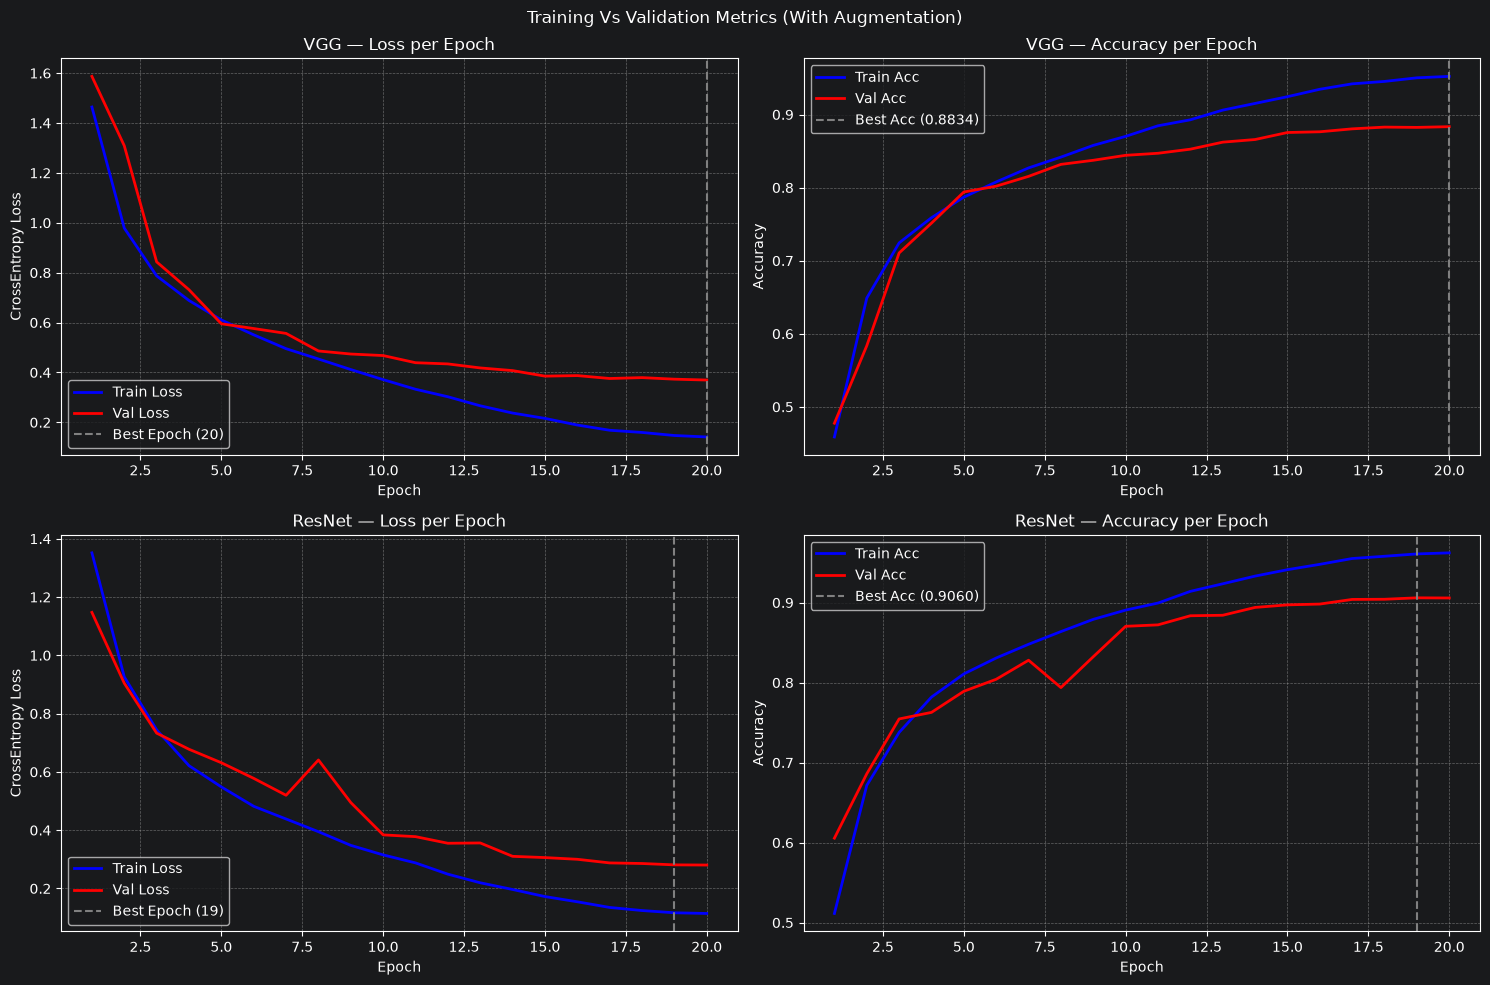

In [8]:
plot_losses(cfg, "vgg_augmented_history.json", "resnet_augmented_history.json",
            "Training Vs Validation Metrics (With Augmentation)")

## Оценка и сравнение моделей на тестовой выборке (`Test`)

Проверим все 4 сохранённые модели на независимой тестовой выборке `test_loader` (10 000 картинок, которые сети ни разу не видели ни на обучении, ни на валидации). Все функции для расчёта метрик и отрисовки вынесены в **`src/metrics.py`**:

1. **Функция `evaluate_checkpoint`:**
   * Загружает лучшие сохранённые веса модели из папки `checkpoints/` (`*_best.pt`) через `model.load_state_dict(torch.load(...))`, переключает сеть в режим `model.eval()` и без расчёта градиентов (`torch.no_grad()`) собирает предсказания по всему `test_loader`.
   * С помощью функций `accuracy_score` и `precision_recall_fscore_support(..., average="macro")` из `sklearn.metrics` считает основные метрики качества.
   * Вызывает вспомогательную функцию **`count_parameters(model)`**, которая суммирует число всех обучаемых весов (`p.numel() for p in model.parameters() if p.requires_grad`), и подтягивает время обучения и номер лучшей эпохи из JSON-лога через `load_log`.
2. **Функция `plot_confusion_matrices`:** строит матрицы ошибок $10 \times 10$ (`confusion_matrix` и `ConfusionMatrixDisplay`) для базовых и аугментированных моделей, чтобы увидеть, какие именно классы сети путают между собой.
3. **Сводная таблица (`comparison_df`):** собираем результаты всех четырёх прогонов в единый `pd.DataFrame` и выводим через `display()`.


,Model,Accuracy,Precision (macro),Recall (macro),F1-score (macro),Parameters,Train time,Best epoch
0,VGG (Base),0.8134,0.8233,0.8134,0.8145,"4,967,946",99.00,11
1,ResNet (Base),0.8144,0.8140,0.8144,0.8121,"4,903,242",258.37,15
2,VGG (Augmented),0.8814,0.8809,0.8814,0.8810,"4,967,946",99.44,20
3,ResNet (Augmented),0.9080,0.9077,0.9080,0.9078,"4,903,242",260.13,19


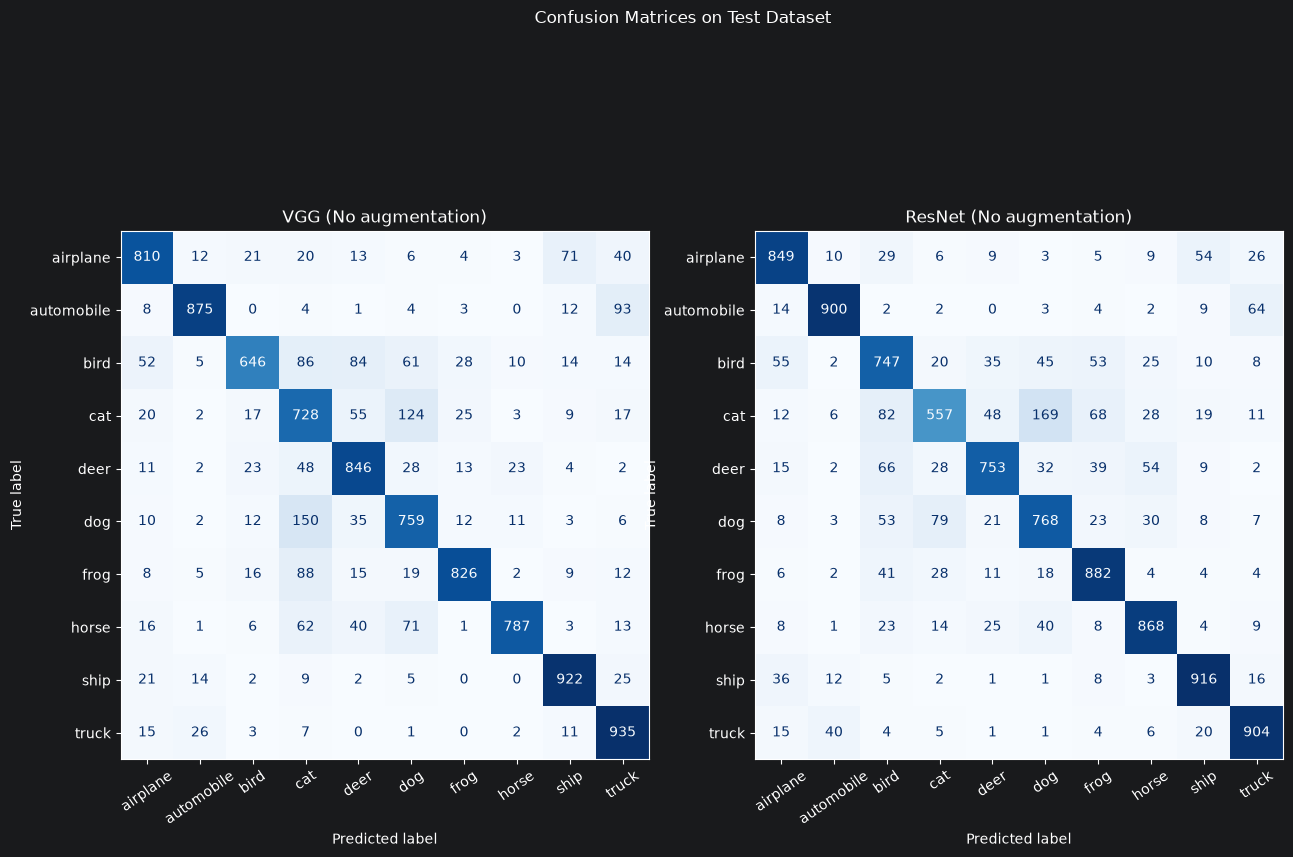

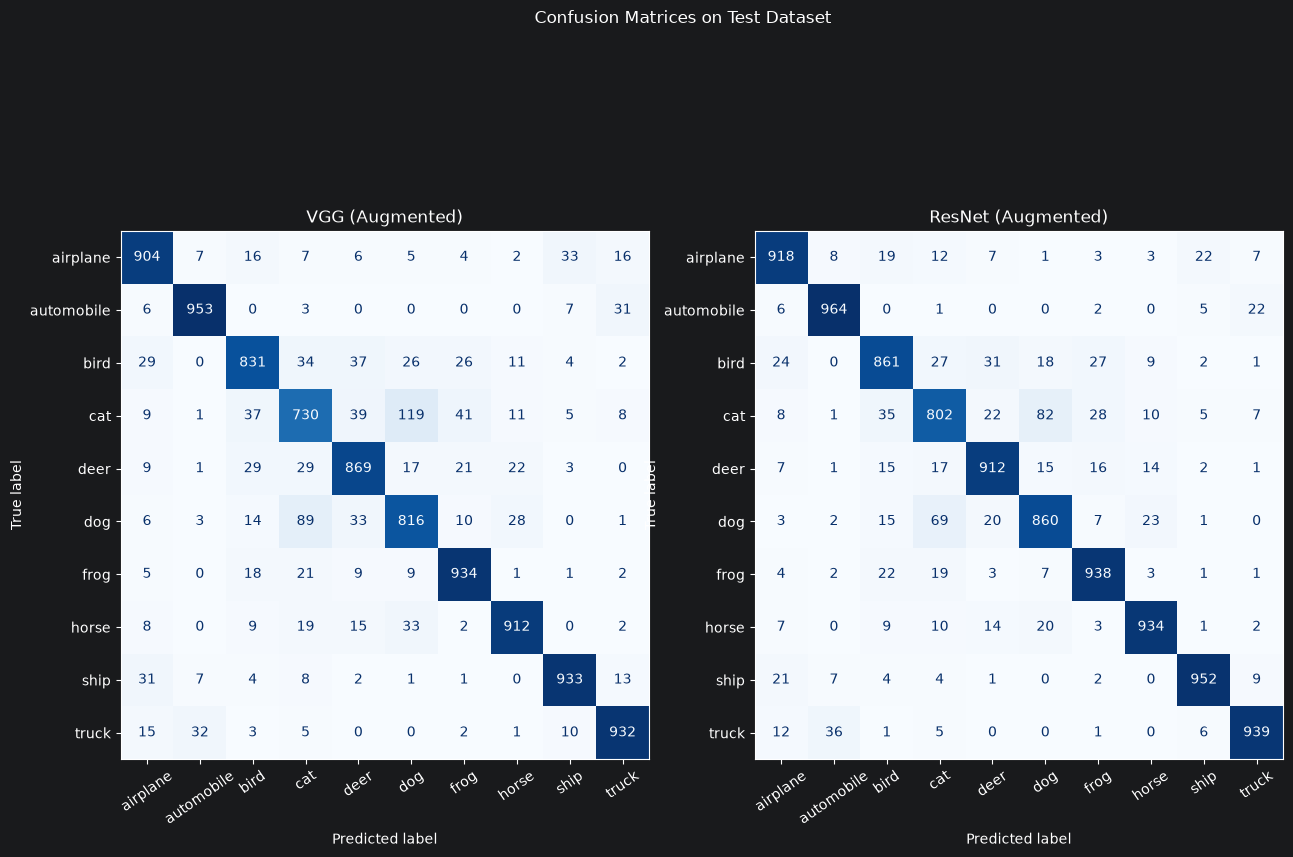

In [9]:
vgg_base_row, vgg_y_true, vgg_y_pred = evaluate_checkpoint(VGG(cfg.num_classes), "vgg", "VGG (Base)", test_loader, cfg)
res_base_row, res_y_true, res_y_pred = evaluate_checkpoint(ResNet(cfg.num_classes), "resnet", "ResNet (Base)",
                                                           test_loader, cfg)

vgg_aug_row, vgg_aug_y_true, vgg_aug_y_pred = evaluate_checkpoint(VGG(cfg.num_classes), "vgg_augmented",
                                                                  "VGG (Augmented)",
                                                                  test_loader, cfg)
res_aug_row, res_aug_y_true, res_aug_y_pred = evaluate_checkpoint(ResNet(cfg.num_classes), "resnet_augmented",
                                                                  "ResNet (Augmented)", test_loader, cfg)

plot_confusion_matrices([
    ("VGG (No augmentation)", vgg_y_true, vgg_y_pred),
    ("ResNet (No augmentation)", res_y_true, res_y_pred)
])

plot_confusion_matrices([
    ("VGG (Augmented)", vgg_aug_y_true, vgg_aug_y_pred),
    ("ResNet (Augmented)", res_aug_y_true, res_aug_y_pred)
])

comparison_df = pd.DataFrame([vgg_base_row, res_base_row, vgg_aug_row, res_aug_row])
display(comparison_df)


## Итоговые выводы по лабораторной работе

В этой работе мы разобрали на практике операцию двумерной свёртки (`F.conv2d`), а затем с нуля собрали в `src/models.py`, обучили в `src/trainer.py` и протестировали через `src/metrics.py` две архитектуры свёрточных сетей — **VGG** и **ResNet** на датасете **CIFAR-10**.

### Ответы на вопросы по результатам экспериментов:

1. **Какая архитектура показала лучшее качество и почему?**
   * Лучший результат на тестовой выборке `test_loader` (10 000 картинок) выдала модель **ResNet (Augmented)**: по расчётам функции `evaluate_checkpoint` она набрала **`Accuracy = 0.9080` (90.80%)**, **`Precision = 0.9077`**, **`Recall = 0.9080`** и **`F1-score = 0.9078`**, обогнав **VGG (Augmented)** (`Accuracy = 0.8814`, `F1-score = 0.8810`) на **2.66%**.
   * **Почему победила `ResNet`:**
     * **Обходные связи (`self.shortcut` в классе `ResNetBlock`):** за счёт сложения `conv_block(x) + shortcut(x)` градиенты при вызове `loss.backward()` свободно доходят до самых первых слоёв без затухания, а блокам проще учить небольшую поправку к сигналу, чем весь признак с нуля.
     * **Сохранение деталей на старте:** в `ResNet` в начальном блоке `self.prep` нет `MaxPool2d`, поэтому первые слои работают с полной картинкой $32 \times 32$ и не теряют мелкие детали.
     * **Лёгкий выходной слой:** вместо тяжёлого блока `self.classifier` из двух `nn.Linear` (как в `VGG`), в `ResNet` стоит `nn.AdaptiveAvgPool2d((1, 1))` и один компактный слой `nn.Linear(512, 10)`, который меньше склонен к переобучению.

2. **Какая модель оказалась более сложной и дольше обучалась?**
   * **По числу весов (`count_parameters` в `src/metrics.py`):** обе модели почти одинаковые, причём `ResNet` даже чуть легче — **`4,903,242`** параметра против **`4,967,946`** у `VGG`.
   * **По времени обучения (`total_time_sec` из логов):** гораздо тяжелее в расчётах оказалась **ResNet** — 20 эпох заняли **`258.37–260.13 с`** (~13 с на эпоху) против **`99.00–99.44 с`** (~4.9 с на эпоху) у **VGG**. Разница в **2.6 раза** возникает потому, что `VGG` после первого же блока сжимает картинку через `nn.MaxPool2d(2, 2)` с $32 \times 32$ до $16 \times 16$ (пикселей становится в 4 раза меньше), а `ResNet` считает весь первый блок (`prep` + `layer1`) на полном разрешении $32 \times 32$.

3. **Были ли проблемы с переобучением и как они решались?**
   * Да, при базовом обучении (`augment=False`) обе сети сильно переобучались уже после 5–6 эпохи: точность на `train` улетала к `99%`, ошибка `val_loss` начинала расти (до `1.28` у `VGG` и `0.92–1.00` у `ResNet`), а точность на тесте застревала на **`81.34%` (VGG)** и **`81.44%` (ResNet)**.
   * **Как исправили:** в `src/trainer.py` добавили функцию **`gpu_augment`**, которая на лету отражает половину картинок в батче по горизонтали (`torch.flip`) и делает случайный сдвиг на 4 пикселя (`F.pad` + срез $32 \times 32$), а также подключили косинусный планировщик **`CosineAnnealingLR`** (`scheduler.step()`), плавно снижающий `learning_rate` к 20-й эпохе.
   * **Итог:** `val_loss` перестал расти и плавно снижался все 20 эпох, а точность на тестовой выборке выросла на **+6.80%** у `VGG` (до `88.14%`) и на **+9.36%** у `ResNet` (до `90.80%`).

4. **Какие ошибки чаще всего совершали модели?**
   * Судя по матрицам ошибок (`plot_confusion_matrices` в `src/metrics.py`), лучше всего модели узнают транспорт и лягушек (`automobile`, `truck`, `ship`, `frog`) — у них чёткие формы и понятный фон.
   * Чаще всего сети путают между собой визуально похожие классы:
     * **`cat` ↔ `dog`:** самая частая ошибка у обеих моделей. На маленькой картинке $32 \times 32$ черты морды размываются, а шерсть, позы и домашний фон у кошек и собак почти не отличаются.
     * **`automobile` ↔ `truck`:** модели иногда путают легковые машины и грузовики из-за общих деталей (колёса, фары, кабина, асфальт), особенно если машина снята под нестандартным углом.
     * **`deer` ↔ `horse`** и **`bird` ↔ `airplane`:** путаются из-за похожих силуэтов и одинакового фона (зелёный лес/трава у оленей с лошадьми и синее небо у птиц с самолётами).
